la teta es:  59.99999999999999
x normal:  0.5000000000000001
x rotado:  0.5000000000000001
y normal:  0.8660254037844386
y rotado:  0.8660254037844386
Position of ray:  [0.5000000000003901, 6370.866025403784]
Iteracion fuera:  0
la teta es:  59.99999999999999
x normal:  0.5000000000000001
x rotado:  0.5000000000000001
y normal:  0.8660254037844386
y rotado:  0.8660254037844386
Position of ray:  [1.0000105130908707, 6371.866005782805]
Iteracion n1==n0:  1
la teta es:  59.99999999999999
x normal:  0.5000000000000001
x rotado:  0.5000000000000001
y normal:  0.8660254037844386
y rotado:  0.8660254037844386
Position of ray:  [1.5000105130914831, 6372.73203118659]
Iteracion n1==n0:  2
la teta es:  59.99999999999999
x normal:  0.5000000000000001
x rotado:  0.5000000000000001
y normal:  0.8660254037844386
y rotado:  0.8660254037844386
Position of ray:  [2.0000105130919494, 6373.598056590374]
Iteracion n1==n0:  3
la teta es:  59.99999999999999
x normal:  0.5000000000000001
x rotado:  0.50000000

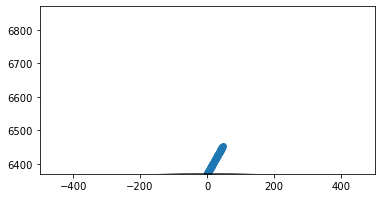

In [145]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patch
import scipy.optimize as optimize


#Import function to obtain electron density:
#Doesn't work
#from ipynb.fs.full.Refraction_index_from_electron_density import ref_index

%run "Refraction_index_from_electron_density.py"

freq = 5e7# Radiofrequency from 50 kHz to 300 GHz, we choose 100 kHz
n=ref_index(freq,elec_dens)


#And the grid distance:
delta_y=1

#We select the velocity of the light:
c=1

# NOW WE NEED TO DO ITERATIONS FOR DIFFERENT FREQUANCIES TO REACH THE END POINT:

destiny=1000 #The x position we want to reach

def GetRayPolar(angle,n):
    c = 1
    delta_r = 1
    
    #The radius of the earth:
    R_Earth=6370
    # initial angle, our initial point is in the "top" of the earth
    phi = np.pi/2 
    #We choose the initial position of the ray:
    
    # Getting the coordinates in (r,phi) polar coordinates
    # Should be easier
    ray=[[R_Earth , phi]]
    
    #We just do iterations:
    step_t=1 #constant, time passing between iterations
    current_index=0 #To see in which pixel we are
    sum_r=0 #The sum of the distance from the centre, to see if it passes to the next cell

    #We track te iterations number too:
    i=0

    #A boolean to stop the iterations:
    boolean=True
    
    # Angle of rotation of each step of the Snell law
    ubre = 1*( np.pi/2 - phi) #Can be negative(don't know)
    
    while boolean: 
        #The n index depends on the height:
        n0=n[current_index]
        print("la teta es: ", angle*180/np.pi)
        x0=step_t*(c/n0)*np.cos(angle)
        y0=step_t*(c/n0)*np.sin(angle)
        
        x = x0 * np.cos(ubre) - y0*np.sin(ubre)
        y = x0 * np.sin(ubre) + y0*np.cos(ubre)
        
        print("x normal: ",x0)
        print("x rotado: ",x)
        
        print("y normal: ",y0)
        print("y rotado: ",y)
        # print("El pinche y:", y)
        #We need to see if we have reached the next height with this last step
        #To do so, we check if the sum is bigger than the grid size:
        '''
        print("sum of height: ",sum_r)
        print("refraction index: ",n0)
        print("angle: ", angle*180/np.pi)
        print("current index: ", current_index)
        print("Angle of rotation: ",ubre)
        '''
        

        mod_r0 =ray[i][0]
        # Vector coordinates
        r1 = [mod_r0*np.cos(ray[i][1]) + x, mod_r0*np.sin(ray[i][1])  + y] 
        print("Position of ray: ",r1)
        #print("r1: ",r1)
        mod_r1 = np.sqrt(r1[0]**2 + r1[1]**2)
        if(n0==0):
            print("Haber estudiao")
            boolean=False
            break
        # print("PREVIOUS sum of height: ",sum_h0)
        if (abs(sum_r + (mod_r1 - mod_r0)>=delta_r)):
            k=1
            while(abs(sum_r+(mod_r1 - mod_r0)-k*delta_r)>delta_r):
                k+=1
            n1=np.mean(n[current_index+1:current_index+k+1])
            # print("n1: ",n1)
            current_index+=k #We go to the next grid
            #See if changes refraction index:
            if (n1==n0):
                # print("n1 is equal to n0")
                #r2=np.sqrt((ray[i-1][0]+x)**2+(ray[i-1][1]+y)**2) #Distance from centre of earth to new point
                #r1=np.sqrt((ray[i-1][0])**2+(ray[i-1][1])**2) #Distance from centre of earth to previous point
                sum_r=sum_r+ (mod_r1-mod_r0) - k*delta_r #Goes to next cell normal
                phi=np.arctan2(r1[1],r1[0])
                print("Iteracion n1==n0: ",i)
                #ubre = -1*( (np.pi/2)-phi ) # the rot angle is negative
                #We add the new total position of our ray:
                ray.append([mod_r1,phi])
                #ray.append([ray[i-1][0]+x,ray[i-1][1]+y])
            else:
                #Snell law to calculate new angle.
                #CAUTION: Snell angle is taken from the normal and ours is from the horizontal axis:
                
                #First the angle from the horizontal:
                theta0=angle #angle0=angle
                
                #Then we need to calculate the angle from the horizontal (passing through the centre)
                #to the new vector position:
                phi_in=ray[i][1]
                
                r_before = (delta_r-sum_r)
                x1 = r_before*np.cos(theta0)
                y1 = r_before*np.sin(theta0)
                ubre0 = 1*(np.pi/2 - phi_in)
                print("Previa ubre: ", ubre0)
                x1_rot = x1*np.cos(ubre0) - y1*np.sin(ubre0)
                y1_rot = x1*np.sin(ubre0) + y1*np.cos(ubre0)
                phi_ideal = np.arctan2(ray[i][0]*np.sin(ray[i][1]) + y1_rot, ray[i][0]*np.cos(ray[i][1]) + x1_rot)
                
                #Finally, we get the angle to use Snell law. Using trigonometry:
            
                alpha_in = 1*(phi_ideal - theta0) # Has to be phi_ideal
                #print("Alpha_in: ",alpha_in*180/np.pi)
                #print("Phi_in: ",phi_in*180/np.pi)
                #CAREFUL: arcsin input has to be between -1 and 1. If it exceedes, add/substract 1
                if (n0==0 or n1==0 or abs((n0*np.sin(alpha_in))/n1)>=1):
                    print("Que n1 es 0 hijueputa")
                    #There has been an internal reflection, the wave can't pass. We stop
                    boolean=False
                else:
                    # print("x expected: ",x)
                    # print("y expected: ",y)
                    # print("sum of y: ",sum_h)
                    # print("n0: ",n0)
                    # print("angle: ",angle0)
                    alpha_out=np.arcsin((n0*np.sin(alpha_in)/n1))
                    theta=(np.pi/2)-alpha_out-theta0
                    print("Theta anterior: ",theta0*180/np.pi)
                    print("Theta posterior: ",theta*180/np.pi)
                    print("Alpha_in: ",alpha_in*180/np.pi)
                    print("Alpha_out: ",alpha_out*180/np.pi)
                    #Now we need to calculate the height.
                    #It divides into two heights:
                    #1)height in previous cell: delta_y-sum_h
                    #2)height in new cell with new angle and n:
                    #######
                    #r_before = (delta_r-sum_r)
                    #vprint("y1: ",y1)
                   # print("THE FUCKING Y1: ",y1)
                    r_after=(c/n1)*np.sin(theta)*(step_t-((delta_r-sum_r)*n0/(c*np.sin(theta0))))
                    r = r_before + r_after
                    #The y can be negative, but the x is always positive (it moves forward)
                    #x1 = r_before*np.cos(theta0)
                    x2 = r_after*np.cos(theta)
                    #y1 = r_before*np.sin(theta0)
                    y2 = r_after*np.sin(theta)
                    # Now we need to rotate the values of x1, x2, y1 and y2 in order to obtain
                    # the angle Phi of the polar coordinates to append it to "Ray"
                    # Before Snell law the rotation is given by
                    #ubre0 = 1*(np.pi/2 - phi_in)
                    #print("Previa ubre: ", ubre0)
                    #x1_rot = x1*np.cos(ubre0) - y1*np.sin(ubre0)
                    #y1_rot = x1*np.sin(ubre0) + y1*np.cos(ubre0)
                    # After Snell law, the new rotation angle
                    # Phi ideal is the polar angle where the Snell law takes place
                    #phi_ideal = np.arctan2(ray[i-1][0]*np.sin(ray[i-1][1]) + y1_rot, ray[i-1][0]*np.cos(ray[i-1][1]) + x1_rot)
                    
                    ubre = np.pi/2-phi_ideal
                    print("Ubre posterior: ", ubre)
                    print("Iteracion: ", i)
                    x2_rot = x2*np.cos(ubre) - y2*np.sin(ubre)
                    y2_rot = x2*np.sin(ubre) + y2*np.cos(ubre)                
                    #print("x real: ",x)
                    #print("y real: ",y)
                    #print("n1: ",n1)
                    #print("angle: ",angle)
                    #We put the sum back to current height in next cell, to count again:
                    sum_r = r_after
                    x_new = ray[i][0]*np.cos(ray[i][1])+x1_rot+x2_rot
                    y_new = ray[i][0]*np.sin(ray[i][1])+y1_rot+y2_rot
                    phi_out = np.arctan2(y_new,x_new)
                    #We add the new total position of our ray:
                    ray.append([ray[i][0] + r,phi_out])
                    angle=theta
            
        else:
            #If it doesn't jump to next cell the ray will travel normally:
            r = np.sqrt(x**2 + y**2)
            r0 = ray[i][0]
            phi0 = ray[i][1]
            phi = np.arctan2(r0*np.sin(phi0)+y,r0*np.cos(phi0)+x)
            print("Iteracion fuera: ",i)
            ray.append([(ray[i][0] + r), phi])
            # print("El pinche y:", y)
            # print("The previous sum_h: ",sum_h)
            # print("la suma: ",sum_h+y)
            #sum_h=sum_h+y
            sum_r+=np.sqrt(x**2+y**2)
            # print("The new sum_h: ",sum_h)

        #Next iteration:
        i+=1
        # print(boolean)
    return ray



def GetLastPosition(angle):
    ray=GetRay(angle,n)
    return (ray[-1][0]-(destiny/2))


#Now We have the right angle:
#right_angle=optimize.fsolve(GetLastPosition,(50*np.pi/180))
#print(right_angle*180/np.pi)
ray=GetRay((50*np.pi/180),n)
ray2=GetRayPolar((60*np.pi/180),n)
#print(ray2)

#Draw a circle:


figure, axes = plt.subplots()


x_axis=[]
y_axis=[]
for j in range(len(ray)):
    x_axis.append(ray[j][0])
    y_axis.append(ray[j][1])
#print(y_axis)

#axes.scatter(x_axis,y_axis)

x_axis2=[]
y_axis2=[]
for j in range(len(ray2)):
    r = ray2[j][0]
    phi = ray2[j][1]
    x_axis2.append(r*np.cos(phi))
    y_axis2.append(r*np.sin(phi))
#print(y_axis2)

axes.scatter(x_axis2,y_axis2)


# ONCE WE HAVE THE CORRECT RAY WE DO AN ANDRES
destiny=ray2[-1][0]*2

andres=[]
for j in range (len(ray2)):
    andres.append([destiny-ray2[j][0],ray2[j][1]])
x_axis2=[]
y_axis2=[]
for j in range(len(andres)):
    x_axis2.append(andres[j][0])
    y_axis2.append(andres[j][1])
#print(y_axis)
#axes.scatter(x_axis2,y_axis2)

#The radius of the earth:
R_Earth=6370
axes.set_xlim(-500,500)
axes.set_ylim(R_Earth,R_Earth+500)
axes.set_aspect( 1 )
circ=patch.Circle((0,0),R_Earth,fill=False) #A circle centered at (0,0) with radius 100
axes.add_artist( circ )
#plt.title( 'Circle' )
plt.show()
